# Stream A — NER Pipeline (Option B)

VisualNews `data.json` is gated — captions are not available for NewsCLIPpings.
NER is therefore run on **VERITE** and **MMFakeBench** (both have caption text),
and NewsCLIPpings entity cache is saved as empty dicts (entity scorer will fall
back to CLIP similarity for those pairs).

**Caption sources:**
- VERITE → `data/verite/VERITE.csv` — `caption` column (1,001 rows)
- MMFakeBench → `data/mmfakebench/MMFakeBench_test.json` — `text` field (10,000 rows)

**Outputs (auto-saved):**
- `cache/ner/entities_newsclippings_{split}.pkl` — empty dicts (placeholder)
- `cache/ner/entities_verite.pkl` — `{idx: [{text,label,start,end}, ...]}`
- `cache/ner/entities_mmfake.pkl` — `{idx: [{text,label,start,end}, ...]}`
- `cache/ner/entities_all.pkl` — merged dict
- `paper/tables/ner_entity_stats.csv`
- `paper/tables/ner_entity_richness_ooc_vs_genuine.csv`
- `paper/figures/ner_entity_distribution.png`
- `paper/figures/ner_entity_count_histogram.png`
- `paper/figures/ner_entity_ooc_vs_genuine.png`

**Order:** `env_check` → `data_download` → `eda` → **`ner_pipeline`** → `visual_grounding`

## 1. Environment

In [13]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'}")
if torch.cuda.is_available():
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 8.6 GB


In [14]:
import sys, pickle, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
from tqdm import tqdm

sys.path.insert(0, str(Path("../../").resolve()))
from src.utils.paths import *
from src.utils.io import load_json

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

NER_CACHE    = CACHE / "ner"
PAPER_FIGS   = ROOT  / "paper" / "figures"
PAPER_TABLES = ROOT  / "paper" / "tables"
for d in [NER_CACHE, PAPER_FIGS, PAPER_TABLES]:
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    p = PAPER_FIGS / f"{name}.png"
    plt.savefig(p, bbox_inches="tight", dpi=150)
    print(f"  Saved → {p.relative_to(ROOT)}")

def savecsv(df, name):
    p = PAPER_TABLES / f"{name}.csv"
    df.to_csv(p, index=False)
    print(f"  Saved → {p.relative_to(ROOT)}")

print(f"Setup done. NER cache → {NER_CACHE.relative_to(ROOT)}")

Setup done. NER cache → cache\ner


## 2. Load SpaCy model

In [15]:
SPACY_MODEL = None
for model_name in ["en_core_web_trf", "en_core_web_sm"]:
    try:
        nlp = spacy.load(model_name, disable=["tagger", "parser", "lemmatizer"])
        SPACY_MODEL = model_name
        print(f"  ✓  Loaded {model_name}")
        break
    except OSError:
        print(f"  ⚠  {model_name} not found — trying next...")

if SPACY_MODEL is None:
    raise RuntimeError("No SpaCy model found. Run: python -m spacy download en_core_web_sm")

doc = nlp("Barack Obama visited Paris on Monday.")
print(f"  Smoke test: {[(e.text, e.label_) for e in doc.ents]}")

  ⚠  en_core_web_trf not found — trying next...
  ✓  Loaded en_core_web_sm
  Smoke test: [('Barack Obama', 'PERSON'), ('Paris', 'GPE'), ('Monday', 'DATE')]


## 3. NER helper

In [16]:
ENTITY_TYPES_OF_INTEREST = {
    "PERSON", "ORG", "GPE", "LOC", "EVENT", "FAC", "PRODUCT", "NORP", "WORK_OF_ART"
}

def run_ner_batch(ids, texts, cache_path, desc="NER"):
    """Run NER with nlp.pipe, save to cache_path, return dict."""
    if cache_path.exists():
        ents = pickle.load(open(cache_path, "rb"))
        print(f"  ✓  {desc}: loaded from cache ({len(ents):,} entries)")
        return ents

    print(f"  Running {desc} on {len(texts):,} texts ...")
    t0 = time.time()
    ents = {}
    BATCH = 256
    for i in tqdm(range(0, len(texts), BATCH), desc=desc):
        b_ids   = ids[i : i + BATCH]
        b_texts = [t.strip() if t else "" for t in texts[i : i + BATCH]]
        docs = list(nlp.pipe(b_texts, batch_size=BATCH))
        for pid, doc in zip(b_ids, docs):
            ents[pid] = [
                {"text": e.text, "label": e.label_, "start": e.start_char, "end": e.end_char}
                for e in doc.ents if e.label_ in ENTITY_TYPES_OF_INTEREST
            ]
    pickle.dump(ents, open(cache_path, "wb"), protocol=4)
    print(f"  ✓  {desc}: {len(ents):,} entries | {time.time()-t0:.1f}s | → {cache_path.name}")
    return ents

print("NER helper ready.")

NER helper ready.


## 4. NewsCLIPpings — placeholder cache

VisualNews `data.json` is gated. Saving empty dicts so downstream notebooks
don't crash — entity scorer will use CLIP similarity fallback for these pairs.

In [17]:
def load_newsclip(split):
    fpath = NEWSCLIP / f"{split}.json"
    if not fpath.exists():
        print(f"  ✗  {fpath} not found"); return []
    raw = load_json(fpath)
    return raw.get("annotations", raw) if isinstance(raw, dict) else raw

nc_entities = {}  # merged across splits

for split in ["train", "val", "test"]:
    cache_path = NER_CACHE / f"entities_newsclippings_{split}.pkl"
    if cache_path.exists():
        e = pickle.load(open(cache_path, "rb"))
        print(f"  ✓  newsclippings/{split}: cache exists ({len(e):,} entries)")
        nc_entities.update(e)
        continue
    pairs = load_newsclip(split)
    empty = {str(row["id"]): [] for row in pairs}
    pickle.dump(empty, open(cache_path, "wb"), protocol=4)
    print(f"  ✓  newsclippings/{split}: {len(empty):,} placeholder entries saved")
    nc_entities.update(empty)

print(f"  NewsCLIPpings total: {len(nc_entities):,} entries (all empty — no caption source)")

  ✓  newsclippings/train: cache exists (35,536 entries)
  ✓  newsclippings/val: cache exists (3,512 entries)
  ✓  newsclippings/test: cache exists (3,632 entries)
  NewsCLIPpings total: 42,680 entries (all empty — no caption source)


## 5. VERITE — NER on captions

In [18]:
verite_file = VERITE / "VERITE.csv"
assert verite_file.exists(), f"Not found: {verite_file}"

verite_df = pd.read_csv(verite_file)
# Preserve original label before binarising
if "label" in verite_df.columns and verite_df["label"].dtype == object:
    verite_df["label_orig"] = verite_df["label"]
    verite_df["label"] = (verite_df["label"].str.lower() == "out-of-context").astype(int)

print(f"  VERITE: {len(verite_df):,} rows | columns: {list(verite_df.columns)}")

v_ids   = [f"verite_{i}" for i in range(len(verite_df))]
v_texts = verite_df["caption"].fillna("").tolist()

verite_ents = run_ner_batch(
    v_ids, v_texts,
    NER_CACHE / "entities_verite.pkl",
    desc="NER VERITE"
)

# Attach label info for analysis
verite_df["ner_id"]    = v_ids
verite_df["n_entities"] = [len(verite_ents.get(vid, [])) for vid in v_ids]

  VERITE: 1,001 rows | columns: ['Unnamed: 0', 'caption', 'image_path', 'label']
  ✓  NER VERITE: loaded from cache (1,001 entries)


## 6. MMFakeBench — NER on captions

In [19]:
mmfake_file = DATA / "mmfakebench" / "MMFakeBench_test.json"
assert mmfake_file.exists(), f"Not found: {mmfake_file}"

raw = load_json(mmfake_file)
mm_pairs = raw if isinstance(raw, list) else list(raw.values())
mmfake_df = pd.DataFrame(mm_pairs)
mmfake_df["label"] = (mmfake_df["gt_answers"].str.lower() == "fake").astype(int)

print(f"  MMFakeBench: {len(mmfake_df):,} rows | columns: {list(mmfake_df.columns)}")

mm_ids   = [f"mmfake_{i}" for i in range(len(mmfake_df))]
mm_texts = mmfake_df["text"].fillna("").tolist()

mmfake_ents = run_ner_batch(
    mm_ids, mm_texts,
    NER_CACHE / "entities_mmfake.pkl",
    desc="NER MMFake"
)

mmfake_df["ner_id"]     = mm_ids
mmfake_df["n_entities"] = [len(mmfake_ents.get(mid, [])) for mid in mm_ids]

  MMFakeBench: 10,000 rows | columns: ['text', 'image_path', 'text_source', 'image_source', 'gt_answers', 'fake_cls', 'label']
  ✓  NER MMFake: loaded from cache (10,000 entries)


## 7. Merge all caches

In [20]:
all_entities = {}
all_entities.update(nc_entities)
all_entities.update(verite_ents)
all_entities.update(mmfake_ents)

merged_path = NER_CACHE / "entities_all.pkl"
pickle.dump(all_entities, open(merged_path, "wb"), protocol=4)
print(f"  Merged: {len(all_entities):,} total entries → {merged_path.name}")
print(f"    NewsCLIPpings : {len(nc_entities):,} (placeholder — no captions)")
print(f"    VERITE        : {len(verite_ents):,}")
print(f"    MMFakeBench   : {len(mmfake_ents):,}")

  Merged: 53,681 total entries → entities_all.pkl
    NewsCLIPpings : 42,680 (placeholder — no captions)
    VERITE        : 1,001
    MMFakeBench   : 10,000


## 8. Entity statistics (VERITE + MMFakeBench)

In [21]:
# Stats only on datasets that actually have entities
active_ents = {**verite_ents, **mmfake_ents}

type_counter   = Counter()
entity_per_pair = []
has_entity = 0

for pid, ents in active_ents.items():
    entity_per_pair.append(len(ents))
    if ents: has_entity += 1
    for e in ents:
        type_counter[e["label"]] += 1

total_ents = sum(type_counter.values())
print(f"  Total entities : {total_ents:,}")
print(f"  Pairs with ≥1  : {has_entity:,} / {len(active_ents):,} "
      f"({has_entity/max(len(active_ents),1)*100:.1f}%)")
print(f"  Avg per pair   : {np.mean(entity_per_pair):.2f}  "
      f"(median={np.median(entity_per_pair):.1f}, max={max(entity_per_pair) if entity_per_pair else 0})")
print()
for etype, cnt in type_counter.most_common():
    print(f"    {etype:<20}  {cnt:>7,}  ({cnt/max(total_ents,1)*100:.1f}%)")

stats_df = pd.DataFrame(
    [(t, c, round(c/max(total_ents,1)*100, 2)) for t, c in type_counter.most_common()],
    columns=["entity_type", "count", "pct"]
)
savecsv(stats_df, "ner_entity_stats")

  Total entities : 17,007
  Pairs with ≥1  : 7,764 / 11,001 (70.6%)
  Avg per pair   : 1.55  (median=1.0, max=10)

    PERSON                  6,325  (37.2%)
    ORG                     4,263  (25.1%)
    GPE                     3,800  (22.3%)
    NORP                    1,160  (6.8%)
    FAC                       515  (3.0%)
    LOC                       356  (2.1%)
    WORK_OF_ART               242  (1.4%)
    EVENT                     209  (1.2%)
    PRODUCT                   137  (0.8%)
  Saved → paper\tables\ner_entity_stats.csv


## 9. Visualize entity distribution

  Saved → paper\figures\ner_entity_distribution.png


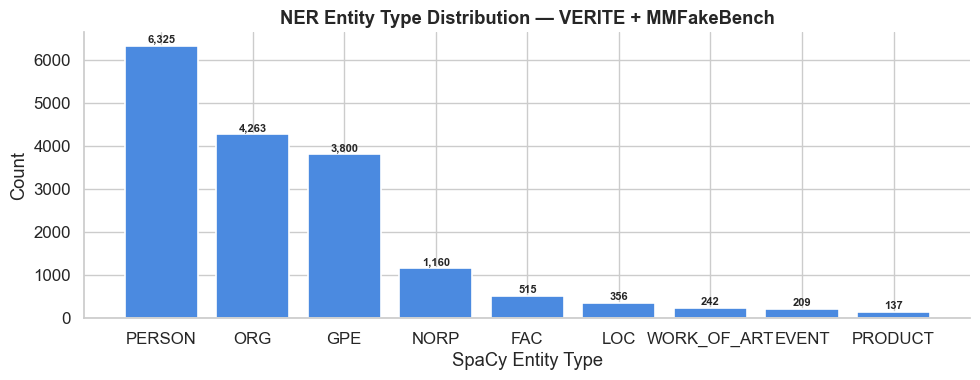

  Saved → paper\figures\ner_entity_count_histogram.png


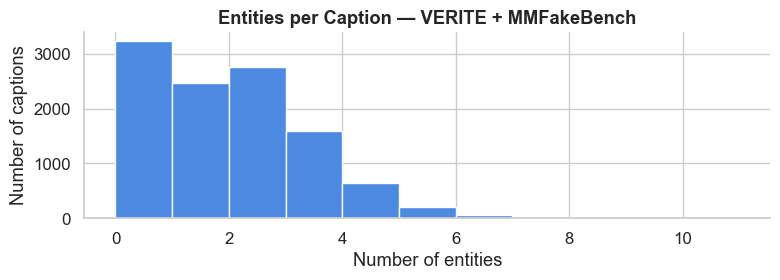

In [22]:
if type_counter:
    labels = [t for t, _ in type_counter.most_common()]
    counts = [c for _, c in type_counter.most_common()]

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(labels, counts, color="#4B8AE0", edgecolor="white", linewidth=1.2)
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + total_ents * 0.002,
            f"{int(bar.get_height()):,}",
            ha="center", va="bottom", fontsize=8, fontweight="bold"
        )
    ax.set_title("NER Entity Type Distribution — VERITE + MMFakeBench", fontweight="bold")
    ax.set_ylabel("Count")
    ax.set_xlabel("SpaCy Entity Type")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    savefig("ner_entity_distribution")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 3))
    max_bin = min(int(max(entity_per_pair))+2, 25) if entity_per_pair else 10
    ax.hist(entity_per_pair, bins=range(0, max_bin),
            color="#4B8AE0", edgecolor="white", linewidth=1.0)
    ax.set_title("Entities per Caption — VERITE + MMFakeBench", fontweight="bold")
    ax.set_xlabel("Number of entities")
    ax.set_ylabel("Number of captions")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    savefig("ner_entity_count_histogram")
    plt.show()

## 10. OOC vs Genuine entity richness

  OOC     — mean: 1.536  median: 1.0  n=7,663
  Genuine — mean: 1.569  median: 1.0  n=3,338
  Saved → paper\figures\ner_entity_ooc_vs_genuine.png


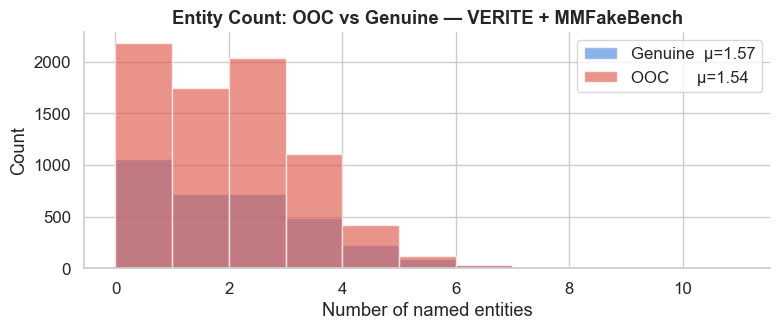

  Saved → paper\tables\ner_entity_richness_ooc_vs_genuine.csv
  Saved → paper\tables\ner_per_sample_entity_counts.csv


In [23]:
ooc_counts, genuine_counts = [], []
source_rows = []

# VERITE
# Replace lines 5-8 with:
for _, row in verite_df.iterrows():
    n = len(verite_ents.get(row["ner_id"], []))
    lbl = 1 if str(row["label"]).lower() in ("1", "true", "out-of-context") else 0
    (ooc_counts if lbl == 1 else genuine_counts).append(n)
    source_rows.append({"source": "verite", "label": lbl, "n_entities": n})

# MMFakeBench
for _, row in mmfake_df.iterrows():
    n = len(mmfake_ents.get(row["ner_id"], []))
    (ooc_counts if row["label"] == 1 else genuine_counts).append(n)
    source_rows.append({"source": "mmfake", "label": int(row["label"]), "n_entities": n})

ooc_arr = np.array(ooc_counts)
gen_arr = np.array(genuine_counts)

print(f"  OOC     — mean: {ooc_arr.mean():.3f}  median: {np.median(ooc_arr):.1f}  n={len(ooc_arr):,}")
print(f"  Genuine — mean: {gen_arr.mean():.3f}  median: {np.median(gen_arr):.1f}  n={len(gen_arr):,}")

fig, ax = plt.subplots(figsize=(8, 3.5))
max_val = max(ooc_arr.max(), gen_arr.max()) if len(ooc_arr) and len(gen_arr) else 15
bins = range(0, min(int(max_val)+2, 25))
ax.hist(gen_arr, bins=bins, alpha=0.65, color="#4B8AE0",
        label=f"Genuine  μ={gen_arr.mean():.2f}")
ax.hist(ooc_arr, bins=bins, alpha=0.65, color="#E05A4B",
        label=f"OOC      μ={ooc_arr.mean():.2f}")
ax.set_title("Entity Count: OOC vs Genuine — VERITE + MMFakeBench", fontweight="bold")
ax.set_xlabel("Number of named entities")
ax.set_ylabel("Count")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
savefig("ner_entity_ooc_vs_genuine")
plt.show()

richness_df = pd.DataFrame({
    "class":   ["genuine", "ooc"],
    "mean":    [round(gen_arr.mean(), 4), round(ooc_arr.mean(), 4)],
    "median":  [float(np.median(gen_arr)), float(np.median(ooc_arr))],
    "max":     [int(gen_arr.max()), int(ooc_arr.max())],
    "n_pairs": [len(gen_arr), len(ooc_arr)],
})
savecsv(richness_df, "ner_entity_richness_ooc_vs_genuine")

# Full per-sample CSV (useful for entity_scorer downstream)
savecsv(pd.DataFrame(source_rows), "ner_per_sample_entity_counts")

## 11. Per-dataset breakdown

In [24]:
# Entity type breakdown per dataset
for ds_name, ds_ents in [("VERITE", verite_ents), ("MMFakeBench", mmfake_ents)]:
    tc = Counter(e["label"] for ents in ds_ents.values() for e in ents)
    tot = sum(tc.values())
    print(f"\n  {ds_name} — {tot:,} entities across {len(ds_ents):,} samples")
    for etype, cnt in tc.most_common(5):
        print(f"    {etype:<20} {cnt:>6,}  ({cnt/max(tot,1)*100:.1f}%)")


  VERITE — 2,208 entities across 1,001 samples
    GPE                     863  (39.1%)
    PERSON                  458  (20.7%)
    ORG                     451  (20.4%)
    NORP                    266  (12.0%)
    EVENT                    50  (2.3%)

  MMFakeBench — 14,799 entities across 10,000 samples
    PERSON                5,867  (39.6%)
    ORG                   3,812  (25.8%)
    GPE                   2,937  (19.8%)
    NORP                    894  (6.0%)
    FAC                     470  (3.2%)


## 12. Sample inspection

In [25]:
print("=== VERITE samples (≥3 entities) ===")
shown = 0
for _, row in verite_df.iterrows():
    ents = verite_ents.get(row["ner_id"], [])
    if len(ents) >= 3:
        lbl = row.get("label_orig", row["label"])
        print(f"\n  [{lbl}] {str(row['caption'])[:130]}")
        for e in ents:
            print(f"    [{e['label']}] {e['text']}")
        shown += 1
        if shown >= 3: break

print("\n=== MMFakeBench samples (≥3 entities) ===")
shown = 0
for _, row in mmfake_df.iterrows():
    ents = mmfake_ents.get(row["ner_id"], [])
    if len(ents) >= 3:
        print(f"\n  [{row['gt_answers']}] {str(row['text'])[:130]}")
        for e in ents:
            print(f"    [{e['label']}] {e['text']}")
        shown += 1
        if shown >= 3: break

=== VERITE samples (≥3 entities) ===

  [true] Image shows unnamed runway model showcasing designs from Chinese designer and performance artist Sheguang Hu's collection during t
    [NORP] Chinese
    [PERSON] Sheguang Hu's
    [ORG] Mercedes-Benz China Fashion

  [out-of-context] Image shows unnamed runway model showcasing designs from Chinese designer and performance artist Sheguang Hu's collection during t
    [NORP] Chinese
    [PERSON] Sheguang Hu's
    [ORG] Mercedes-Benz China Fashion

  [miscaptioned] 3D model accurately depicting what Joseph, husband of Mary, the mother of Jesus Christ, looked like.
    [PERSON] Joseph
    [PERSON] Mary
    [PERSON] Jesus Christ

=== MMFakeBench samples (≥3 entities) ===

  [True] After the murders Charlie Hebdo s surviving staff left their Paris offices for a temporary home at Liberation newspaper
    [PERSON] Charlie Hebdo
    [GPE] Paris
    [ORG] Liberation

  [True] China s ruling Communist Party is now larger than the entire population o

## 13. Done

In [26]:
print("=" * 55)
print("  NER pipeline complete.")
print("=" * 55)
print()
print("  Cache files:")
for f in sorted(NER_CACHE.glob("*.pkl")):
    print(f"    {f.name:<40} {f.stat().st_size/1e6:.1f} MB")
print()
print("  Figures (PNG):")
for f in sorted(PAPER_FIGS.glob("ner_*.png")):
    print(f"    {f.name}")
print()
print("  Tables (CSV):")
for f in sorted(PAPER_TABLES.glob("ner_*.csv")):
    print(f"    {f.name}")
print()
print(f"  SpaCy model : {SPACY_MODEL}")
print(f"  VERITE      : {len(verite_ents):,} entries")
print(f"  MMFakeBench : {len(mmfake_ents):,} entries")
print(f"  NewsCLIP    : {len(nc_entities):,} entries (placeholder — no caption source)")
print()
print("  Next: notebooks/02_stream_a/visual_grounding.ipynb")

  NER pipeline complete.

  Cache files:
    entities_all.pkl                         1.5 MB
    entities_mmfake.pkl                      0.7 MB
    entities_newsclippings_test.pkl          0.0 MB
    entities_newsclippings_train.pkl         0.4 MB
    entities_newsclippings_val.pkl           0.0 MB
    entities_test.pkl                        0.0 MB
    entities_train.pkl                       0.4 MB
    entities_val.pkl                         0.0 MB
    entities_verite.pkl                      0.1 MB

  Figures (PNG):
    ner_entity_count_histogram.png
    ner_entity_distribution.png
    ner_entity_ooc_vs_genuine.png

  Tables (CSV):
    ner_entity_richness_ooc_vs_genuine.csv
    ner_entity_stats.csv
    ner_per_sample_entity_counts.csv

  SpaCy model : en_core_web_sm
  VERITE      : 1,001 entries
  MMFakeBench : 10,000 entries
  NewsCLIP    : 42,680 entries (placeholder — no caption source)

  Next: notebooks/02_stream_a/visual_grounding.ipynb
